# Bayesian workflows in spatial-extremes

This notebook demonstrates the package's two Bayesian inference routes: curvature-adjusted Bayesian inference for max-stable dependence parameters, and a PyMC hierarchical spatio-temporal GEV model for marginal parameters. They answer different questions and have different assumptions; neither should be mistaken for a full Bayesian joint spatial extremes model.

## Sections
1. Setup
2. Curvature-adjusted Bayesian pairwise likelihood
3. PyMC spatio-temporal Bayesian GEV margins
4. Compare the targets and limitations

Install optional PyMC with `python -m pip install -e ".[bayesian,plotting]"`. The pairwise posterior workflow itself uses the core dependencies. Sampling settings are intentionally small for a demonstration, not for production inference.

## 1. Setup

The first example uses a small fixed site layout and data generated from a Brown-Resnick max-stable model. The second uses the bundled rainfall example, which is synthetic and includes a time trend; the hierarchical GEV will be shown with a standardized time covariate. No external data are fetched.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (
        path
        for path in candidates
        if (path / "Dummy_data" / "extremes_observations.parquet").is_file()
        and (path / "src" / "spatial_extremes").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the repository checkout.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from spatial_extremes import (
    fit_spatiotemporal_gev,
    sample_pairwise_likelihood_posterior,
)
from spatial_extremes.models import BrownResnickModel
from spatial_extremes.plotting import plot_spatial_field

SEED = 31415
print("Project root:", PROJECT_ROOT)

Project root: d:\Users\Andy Yuan\Downloads\spatial-extremes\spatial-extremes


## 2. Curvature-adjusted Bayesian pairwise likelihood

`sample_pairwise_likelihood_posterior` first fits the pairwise composite likelihood, then locally adjusts its curvature using finite-difference sensitivity and replicate-level score variability. By default it uses independent zero-centered Normal priors (standard deviation 2.5) on the model's unconstrained free parameters. The resulting posterior is approximate and local, not a posterior from the full joint spatial likelihood. The function emits a warning because it does not calculate convergence diagnostics; check chain behavior and prior sensitivity before interpretation.

We simulate the example data from the same Brown-Resnick family to demonstrate mechanics. Replicates are independent, sites are columns, and coordinates are in the same units as the range.

In [2]:
pairwise_coordinates = np.array(
    [
        [0.0, 0.0],
        [1.5, 0.0],
        [0.0, 1.5],
        [1.5, 1.5],
        [0.7, 2.2],
    ]
)
pairwise_truth = BrownResnickModel(range_=2.0, alpha=1.2)
pairwise_values = pairwise_truth.simulate(
    pairwise_coordinates,
    n_reps=300,
    rng=np.random.default_rng(SEED),
)
pairwise_columns = [f"site_{index}" for index in range(len(pairwise_coordinates))]
pairwise_data = pl.DataFrame(
    pairwise_values,
    schema=pairwise_columns,
    orient="row",
)
print("Data shape:", pairwise_data.shape)
print("Truth (range, alpha):", (pairwise_truth.range_, pairwise_truth.alpha))
pairwise_data.head()

Data shape: (300, 5)
Truth (range, alpha): (2.0, 1.2)


site_0,site_1,site_2,site_3,site_4
f64,f64,f64,f64,f64
0.760551,1.602167,1.113868,1.194573,1.145543
0.461715,0.432244,0.52114,0.432322,0.245232
0.450407,0.961047,0.594827,1.027171,2.455046
23.478221,65.612835,8.778978,18.135788,14.273161
17.666748,39.374982,8.192182,14.897008,12.799969


In [3]:
pairwise_posterior = sample_pairwise_likelihood_posterior(
    BrownResnickModel,
    pairwise_data,
    pairwise_coordinates,
    n_samples=300,
    burn_in=200,
    thin=1,
    prior_scale=2.5,
    rng=np.random.default_rng(SEED + 1),
)

free_draws = pairwise_posterior.free_param_samples
interpretable_draws = np.array(
    [
        [
            BrownResnickModel.from_free_params(draw).range_,
            BrownResnickModel.from_free_params(draw).alpha,
        ]
        for draw in free_draws
    ]
)
print("Pairwise optimizer converged:", pairwise_posterior.pairwise_fit.converged)
print("Acceptance rate:", round(pairwise_posterior.acceptance_rate, 3))
print("Posterior mean in free parameter space:", pairwise_posterior.posterior_mean_free_params)
print("Posterior mean model:", pairwise_posterior.posterior_mean_model)
print("Range and alpha draws, 5/50/95 percentiles:")
print(np.quantile(interpretable_draws, [0.05, 0.5, 0.95], axis=0))

C:\Windows\Temp\ipykernel_14832\389213428.py:1: UserWarning: Curvature-adjusted pairwise-likelihood inference is an approximate, local adjustment. It assumes independent replicates, treats unit-Frechet margins as known, and does not assess MCMC convergence; check the chain and sensitivity to the prior before interpreting posterior summaries.
  pairwise_posterior = sample_pairwise_likelihood_posterior(


Pairwise optimizer converged: True
Acceptance rate: 0.37
Posterior mean in free parameter space: [0.70059241 0.42566662]
Posterior mean model: BrownResnickModel(range_=np.float64(2.0149460219830337), alpha=np.float64(1.209676847004225), variogram_fn=<function power_variogram at 0x000002695994EF00>)
Range and alpha draws, 5/50/95 percentiles:
[[1.80413187 1.02250869]
 [2.00683223 1.1921129 ]
 [2.29542708 1.5443222 ]]


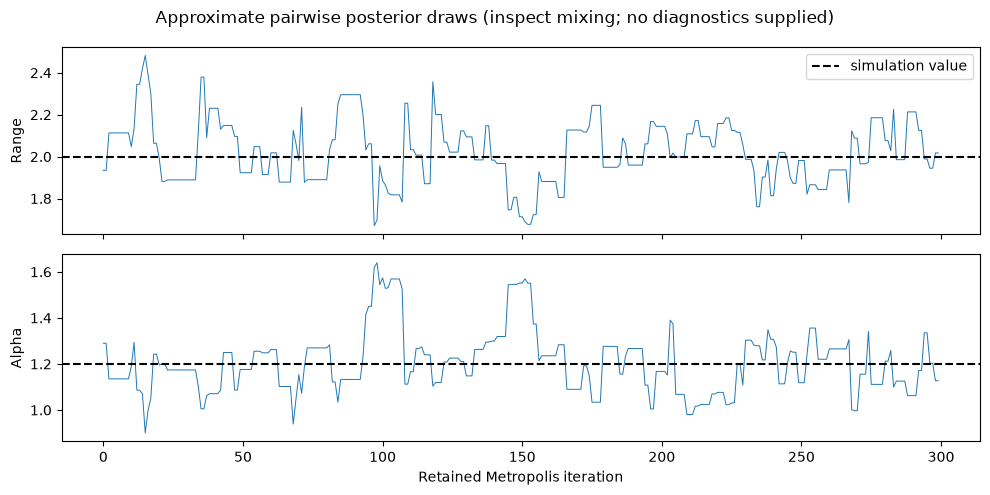

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(interpretable_draws[:, 0], linewidth=0.7)
axes[0].axhline(pairwise_truth.range_, color="black", linestyle="--", label="simulation value")
axes[0].set_ylabel("Range")
axes[0].legend()
axes[1].plot(interpretable_draws[:, 1], linewidth=0.7)
axes[1].axhline(pairwise_truth.alpha, color="black", linestyle="--")
axes[1].set_ylabel("Alpha")
axes[1].set_xlabel("Retained Metropolis iteration")
fig.suptitle("Approximate pairwise posterior draws (inspect mixing; no diagnostics supplied)")
fig.tight_layout()
plt.show()

## 3. PyMC spatio-temporal Bayesian GEV margins

`fit_spatiotemporal_gev` models marginal parameters, not residual spatial extremal dependence. It uses a spatial Matérn-3/2 Gaussian field evolving as an AR(1) for location, static spatial fields for log-scale and shape, and optional standardized time-varying covariates in location. Its dense spatial covariance operations can become expensive as the site count grows. The result includes `posterior_return_levels`.

This demonstration uses six stations and fifty annual maxima from the bundled synthetic dataset. The covariate is a centered time index; it is included to illustrate the API, not because a linear trend is a validated scientific model. Sampling settings are deliberately light; do not use these draws as a production analysis. The example uses `sample_kwargs={"init": "adapt_diag"}` to avoid randomized jittered starting points that can leave the GEV support in a small demonstration; this only controls initialization and does not guarantee convergence.

In [5]:
observations = pl.read_parquet(PROJECT_ROOT / "Dummy_data" / "extremes_observations.parquet")
site_metadata = (
    observations
    .select("station_id", "lon", "lat")
    .unique(subset="station_id", maintain_order=True)
    .head(6)
)
site_names = site_metadata.get_column("station_id").to_list()
subset = observations.filter(pl.col("station_id").is_in(site_names))
wide = (
    subset
    .pivot(on="station_id", index="year", values="annual_max_mm")
    .select("year", *site_names)
    .sort("year")
)
years = wide.get_column("year").to_numpy()
block_maxima = wide.select(site_names).to_numpy()
longitude = site_metadata.get_column("lon").to_numpy()
latitude = site_metadata.get_column("lat").to_numpy()
gev_coordinates = np.column_stack(
    [
        (longitude + 79.0) * 111.0 * np.cos(np.deg2rad(44.0)),
        (latitude - 44.0) * 111.0,
    ]
)
time_covariate = ((years - years.mean()) / years.std())[:, None]
print("Observation matrix (time, site):", block_maxima.shape)
print("Coordinate matrix (site, x/y):", gev_coordinates.shape)
print("Missing observations:", int(np.isnan(block_maxima).sum()))

Observation matrix (time, site): (50, 6)
Coordinate matrix (site, x/y): (6, 2)
Missing observations: 1


In [6]:
# Requires the optional PyMC dependency: python -m pip install "spatial-extremes[bayesian]"
bayesian_gev = fit_spatiotemporal_gev(
    block_maxima,
    gev_coordinates,
    times=years,
    covariates=time_covariate,
    draws=200,
    tune=200,
    chains=2,
    cores=1,
    target_accept=0.9,
    random_seed=SEED,
    sample_kwargs={"init": "adapt_diag"},
)
print("Posterior variables:", list(bayesian_gev.inference_data.posterior.data_vars))

C:\Windows\Temp\ipykernel_14832\2769434104.py:2: UserWarning: This hierarchical GEV model estimates marginal distributions but assumes conditional independence across sites and times. It does not model residual extremal dependence, so uncertainty in joint hazard quantities (such as simultaneous flooding) is likely understated. Do not use this model by itself for joint hazard probabilities.
  bayesian_gev = fit_spatiotemporal_gev(
Initializing NUTS using adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [location_intercept, covariate_effect, location_gp_amplitude, location_gp_length_scale, location_ar1, location_white_noise, log_scale_intercept, log_scale_gp_amplitude, log_scale_gp_length_scale, log_scale_white_noise, shape_intercept, shape_gp_amplitude, shape_gp_length_scale, shape_white_noise]


d:\Users\Andy Yuan\Downloads\spatial-extremes\spatial-extremes\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 200 tune and 200 draw iterations (400 + 400 draws total) took 10 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Posterior variables: ['location_intercept', 'covariate_effect', 'location_white_noise', 'log_scale_intercept', 'log_scale_white_noise', 'shape_intercept', 'shape_white_noise', 'location_gp_amplitude', 'location_gp_length_scale', 'location_ar1', 'log_scale_gp_amplitude', 'log_scale_gp_length_scale', 'shape_gp_amplitude', 'shape_gp_length_scale', 'scale', 'shape', 'location']


In [7]:
return_periods = np.array([20.0, 50.0, 100.0])
return_level_draws = bayesian_gev.posterior_return_levels(
    return_periods,
    time_index=-1,
)
print("Return-level draw array (draw, return period, site):", return_level_draws.shape)

return_level_summary = []
for period_index, period in enumerate(return_periods):
    site_draws = return_level_draws[:, period_index, :]
    for site_index, site in enumerate(site_names):
        lower, median, upper = np.quantile(site_draws[:, site_index], [0.05, 0.5, 0.95])
        return_level_summary.append(
            {
                "site": site,
                "return_period_years": period,
                "q05_mm": lower,
                "median_mm": median,
                "q95_mm": upper,
            }
        )
pl.DataFrame(return_level_summary).head(12)

Return-level draw array (draw, return period, site): (400, 3, 6)


site,return_period_years,q05_mm,median_mm,q95_mm
str,f64,f64,f64,f64
"""S000""",20.0,49.334705,57.189603,65.307332
"""S001""",20.0,52.905827,64.155497,76.742631
"""S002""",20.0,43.621005,50.6345,58.349365
"""S003""",20.0,42.875243,49.68465,57.523793
"""S004""",20.0,31.698002,40.287136,50.485258
…,…,…,…,…
"""S001""",50.0,64.208794,78.523886,96.543186
"""S002""",50.0,49.906229,58.548851,69.684208
"""S003""",50.0,49.009965,57.83429,68.938907


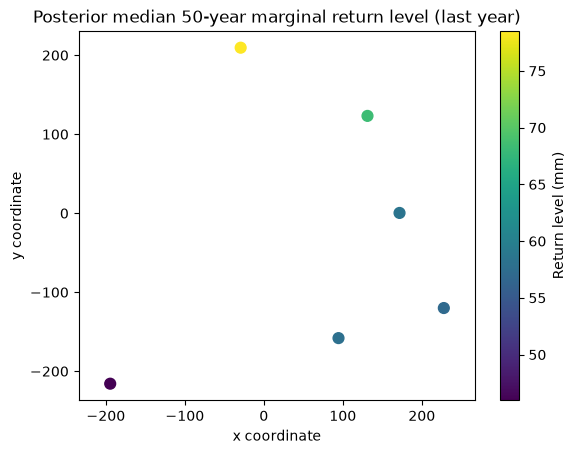

In [8]:
period_index = 1  # 50-year return level
median_50_year = np.median(return_level_draws[:, period_index, :], axis=0)
fig, ax = plot_spatial_field(
    median_50_year,
    gev_coordinates,
    title="Posterior median 50-year marginal return level (last year)",
    colorbar_label="Return level (mm)",
)
plt.show()

## 4. Targets, assumptions, and limitations

| Workflow | Estimates | What it does not model |
|---|---|---|
| Curvature-adjusted Bayesian pairwise likelihood | Dependence parameters for a Smith, Schlather, or Brown-Resnick model | Full joint likelihood, fitted-margin uncertainty, automated convergence diagnostics |
| PyMC spatio-temporal GEV | Spatial/time variation and posterior uncertainty in site-level marginal GEV parameters | Residual extremal dependence or simultaneous-event probabilities |

The pairwise posterior is a local correction to a composite likelihood and can fail when information matrices are not positive definite; the package reports this as an error rather than silently regularizing. The hierarchical GEV model assumes conditional independence across observations, so it must not be used alone to estimate joint spatial hazards. Its `posterior_return_levels` output is marginal at each site.

The intentionally short PyMC run may emit warnings about R-hat and effective sample sizes; those warnings occurred in this demonstration and mean its posterior summaries are not reliable. For an analysis, use multiple chains and substantially more warmup/draws, inspect R-hat, effective sample sizes, divergences, and chain traces, and rerun until diagnostics are satisfactory. Also assess sensitivity to prior choices, validate temporal assumptions, and model residual spatial dependence separately where joint risk is the target.